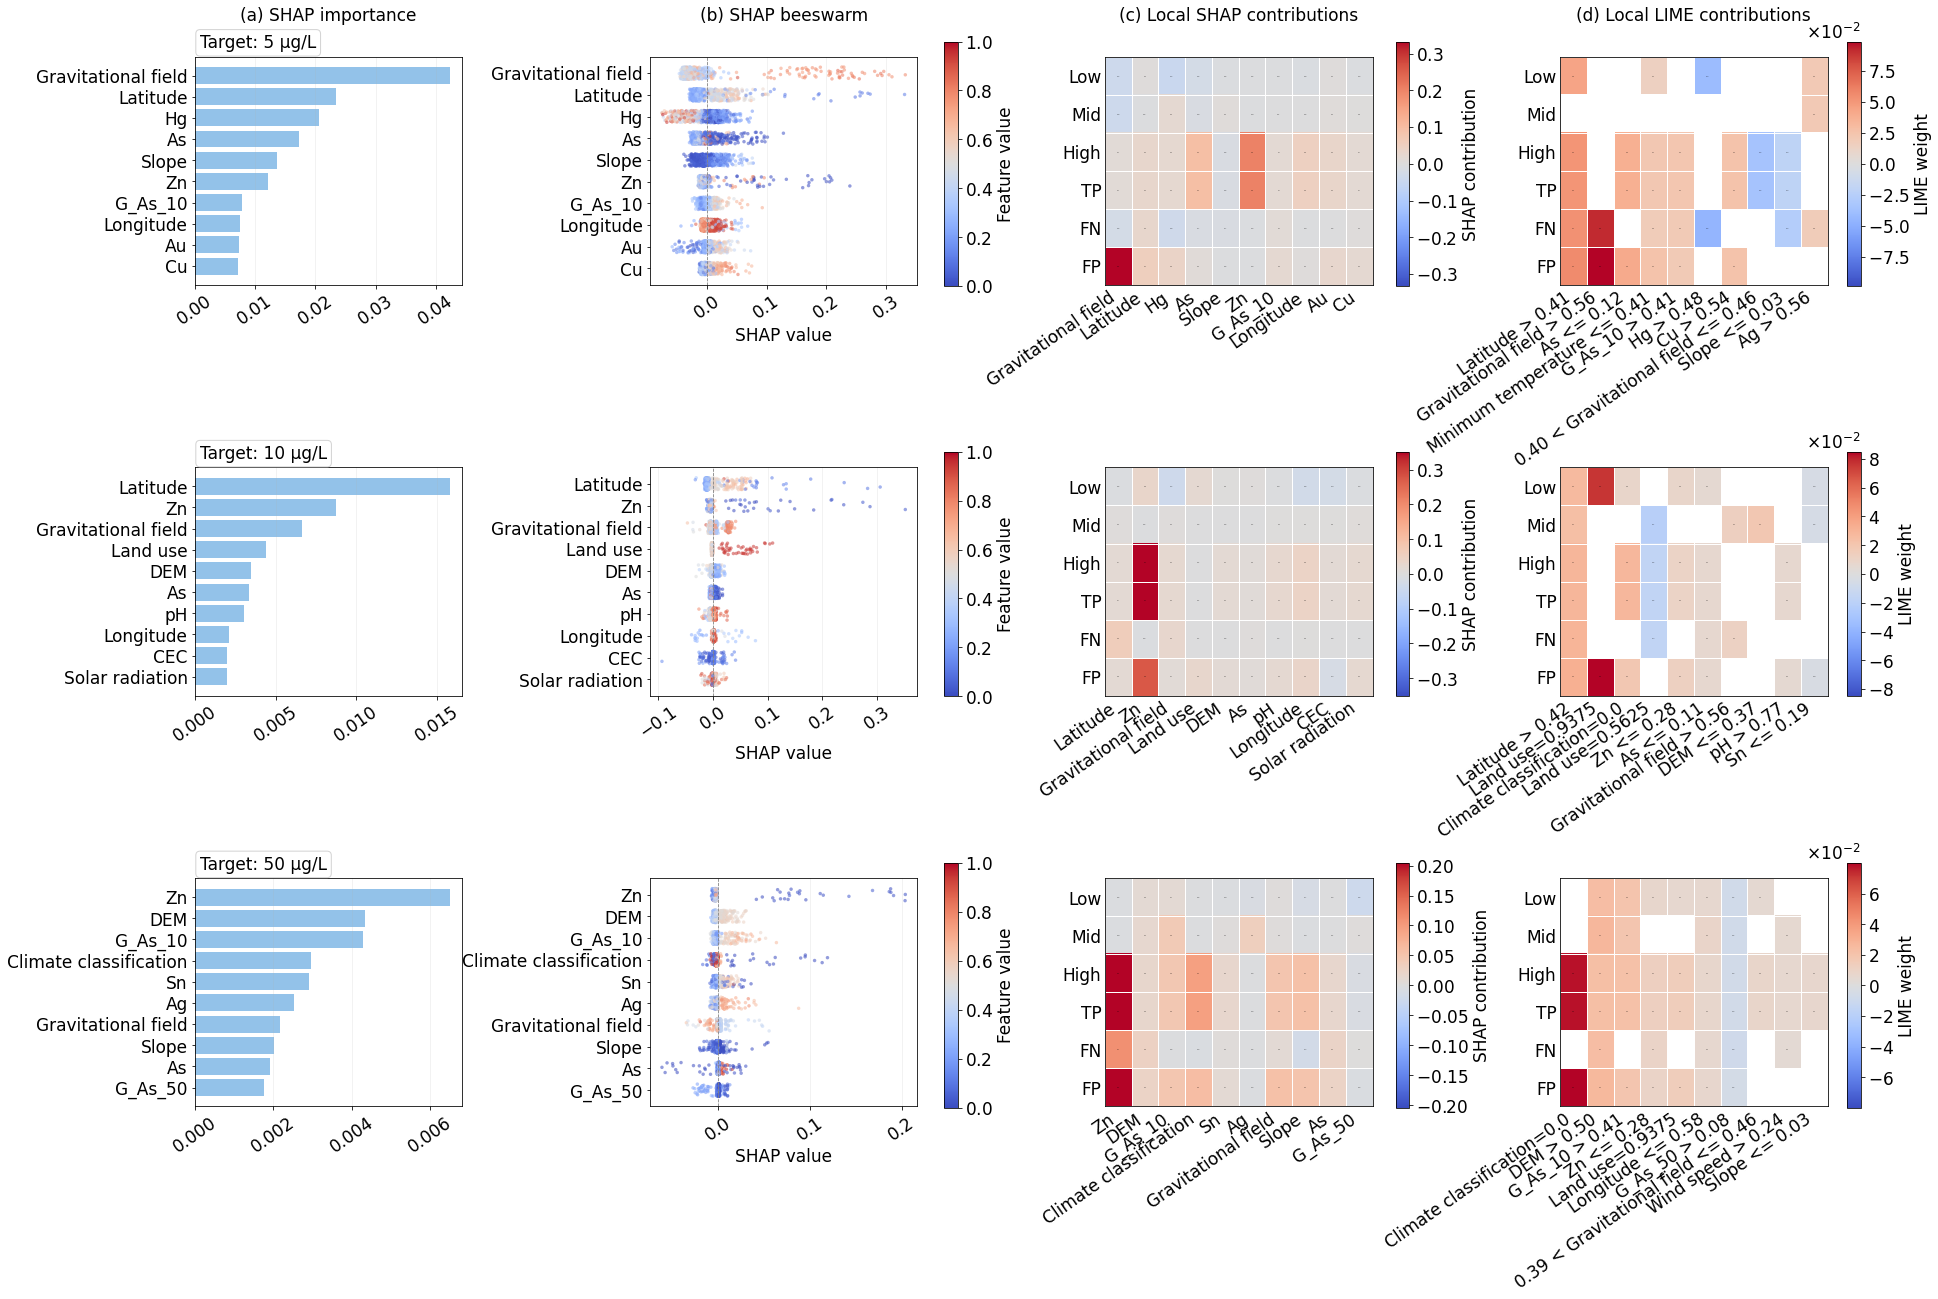

Saved compact 300-DPI summary: E:\NO-NC\submission\revise\SHAP_LIME_compact_summary.jpg


In [114]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import ScalarFormatter  # 引入科学计数法格式化工具

ROOT = Path(r"E:\NO-NC\submission\revise\SHAP_LIME_results")
OUTPUT_JPG = Path(r"E:\NO-NC\submission\revise\SHAP_LIME_compact_summary.jpg")
THRESHOLDS = [5, 10, 50]
N_GLOBAL_FEATURES = 10   # 第一列：top 10 variables
N_LOCAL_FEATURES = 10

# ==================== 统一字号配置变量（可在此处灵活调整） ====================
FONT_TITLE = 17       # 列标题、子图标题字号
FONT_LABEL = 17       # 坐标轴标签、图例标签字号
FONT_TICK = 17        # 坐标轴刻度、图例刻度字号
FONT_ANNOT = 0        # 热力图文本字号
FONT_TEXT = 17        # 目标标签等文本字号
# ==============================================================================

# 加载数据
importance = {}
cases = {}
local = {}
full_shap = {}
for t in THRESHOLDS:
    folder = ROOT / f"threshold_{t}"
    importance[t] = pd.read_csv(folder / "global_shap_importance.csv")
    cases[t] = pd.read_csv(folder / "representative_test_cases.csv")
    local[t] = pd.read_csv(folder / "local_SHAP_LIME_explanations.csv")
    full_shap[t] = pd.read_csv(folder / "full_test_shap_beeswarm_data.csv")

# 创建画布
fig, axes = plt.subplots(3, 4, figsize=(27, 18))

column_titles = [
    "(a) SHAP importance\n",
    "(b) SHAP beeswarm\n",
    "(c) Local SHAP contributions\n",
    "(d) Local LIME contributions\n",
]
for c, title in enumerate(column_titles):
    axes[0, c].set_title(title, fontsize=FONT_TITLE, pad=15)

for row, t in enumerate(THRESHOLDS):
    ax_bar, ax_beeswarm, ax_shap, ax_lime = axes[row]
    
    # ---------------- 第一列：Global SHAP（颜色修改为 #93C2E9） ----------------
    imp = importance[t].sort_values("mean_abs_shap", ascending=False)
    top_global = imp.head(N_GLOBAL_FEATURES).copy().sort_values("mean_abs_shap", ascending=True)
    
    ax_bar.barh(top_global["feature"], top_global["mean_abs_shap"], color="#93C2E9")
    ax_bar.tick_params(axis="y", labelsize=FONT_TICK)
    ax_bar.tick_params(axis="x", rotation=35, labelsize=FONT_TICK)
    ax_bar.grid(axis="x", alpha=0.2)
    
    ax_bar.text(
        0.02, 1.10, f"Target: {t} µg/L",
        transform=ax_bar.transAxes, ha="left", va="top",
        fontsize=FONT_TEXT,
        bbox={"boxstyle": "round,pad=0.25", "facecolor": "white", "alpha": 0.85, "edgecolor": "#cccccc"}
    )

    # 准备测试案例标签
    case_df = cases[t]
    case_ids = case_df["test_row_index"].astype(int).tolist()
    case_labels = []
    for _, case in case_df.iterrows():
        role = str(case["role"])
        label_map = [
            ("low_predicted_risk", "Low"),
            ("intermediate_predicted_risk", "Mid"),
            ("high_predicted_risk", "High"),
            ("true_positive", "TP"),
            ("false_negative", "FN"),
            ("false_positive", "FP"),
        ]
        short = [short for full, short in label_map if full in role]
        case_labels.append("/".join(short) if short else role)

    local_features = imp.head(N_LOCAL_FEATURES)["feature"].tolist()
    local_df = local[t]
    
    beeswarm_features = imp.head(N_LOCAL_FEATURES)["feature"].tolist()
    beeswarm_df = full_shap[t]
    feature_y = {name: i for i, name in enumerate(beeswarm_features)}
    
    # ---------------- 第二列：SHAP Beeswarm ----------------
    rng = np.random.RandomState(2026)
    valid_feature_vals = []
    for feature in beeswarm_features:
        shap_col = f"SHAP__{feature}"
        y_center = feature_y[feature]
        shap_vals = beeswarm_df[shap_col].to_numpy(dtype=float)
        feature_vals = beeswarm_df[feature].to_numpy(dtype=float)
        valid = np.isfinite(shap_vals) & np.isfinite(feature_vals)
        valid_feature_vals.extend(feature_vals[valid].tolist())
        jitter = rng.uniform(-0.28, 0.28, size=int(valid.sum()))
        
        ax_beeswarm.scatter(
            shap_vals[valid], y_center + jitter,
            c=feature_vals[valid], cmap="coolwarm", vmin=0, vmax=1,
            s=12, alpha=0.55, edgecolors="none", rasterized=True
        )
        
    ax_beeswarm.axvline(0, color="gray", linewidth=0.8, linestyle="--")
    ax_beeswarm.set_yticks(np.arange(len(beeswarm_features)))
    ax_beeswarm.set_yticklabels(beeswarm_features, fontsize=FONT_TICK)
    ax_beeswarm.invert_yaxis()
    ax_beeswarm.set_xlabel("SHAP value", fontsize=FONT_LABEL)
    ax_beeswarm.grid(axis="x", alpha=0.2)
    ax_beeswarm.tick_params(axis="x", labelsize=FONT_TICK, rotation=35)
    
    # ---------------- 第三列与第四列：Local 热力图准备 ----------------
    shap_pivot = local_df.pivot_table(
        index="test_row_index", columns="feature", values="shap_value_class1", aggfunc="mean"
    ).reindex(index=case_ids, columns=local_features)
    
    lime_features = (
        local_df.dropna(subset=["lime_weight"])
        .assign(abs_lime=lambda x: x["lime_weight"].abs())
        .groupby("feature")["abs_lime"].sum()
        .sort_values(ascending=False)
        .head(N_LOCAL_FEATURES)
        .index.tolist()
    )
    lime_pivot = local_df.pivot_table(
        index="test_row_index", columns="feature", values="lime_weight", aggfunc="mean"
    ).reindex(index=case_ids, columns=lime_features)

    # 依据当前子图数据单独动态计算数据边界范围（以 0 为中心对称双向归一化）
    sub_shap_vals = shap_pivot.to_numpy(dtype=float)
    sub_shap_max = max(float(np.nanmax(np.abs(sub_shap_vals))), 1e-8)
    norm_sub_shap = TwoSlopeNorm(vmin=-sub_shap_max, vcenter=0, vmax=sub_shap_max)

    sub_lime_vals = lime_pivot.to_numpy(dtype=float)
    sub_lime_max = max(float(np.nanmax(np.abs(sub_lime_vals))), 1e-8)
    norm_sub_lime = TwoSlopeNorm(vmin=-sub_lime_max, vcenter=0, vmax=sub_lime_max)

    # ---------------- 第三列：Local SHAP 热力图（使用 coolwarm 渲染） ----------------
    ax_shap.imshow(np.ma.masked_invalid(sub_shap_vals), cmap="coolwarm", norm=norm_sub_shap, aspect="auto")
    
    # ---------------- 第四列：Local LIME 热力图（使用 coolwarm 渲染） ----------------
    ax_lime.imshow(np.ma.masked_invalid(sub_lime_vals), cmap="coolwarm", norm=norm_sub_lime, aspect="auto")

    # 绘制热力图文字与刻度
    for ax, pivot, feature_labels in [
        (ax_shap, shap_pivot, local_features),
        (ax_lime, lime_pivot, [f.replace("LIME condition: ", "") for f in lime_features]),
    ]:
        ax.set_xticks(np.arange(len(feature_labels)))
        ax.set_xticklabels(feature_labels, rotation=35, ha="right", fontsize=FONT_TICK)
        ax.set_yticks(np.arange(len(case_ids)))
        ax.set_yticklabels(case_labels, fontsize=FONT_TICK)
        ax.set_xticks(np.arange(-0.5, len(feature_labels), 1), minor=True)
        ax.set_yticks(np.arange(-0.5, len(case_ids), 1), minor=True)
        ax.grid(which="minor", color="white", linewidth=1.0)
        ax.tick_params(which="minor", bottom=False, left=False)
        ax.tick_params(axis="both", length=0)
        
        vals = pivot.to_numpy(dtype=float)
        for i in range(vals.shape[0]):
            for j in range(vals.shape[1]):
                if np.isfinite(vals[i, j]):
                    ax.text(j, i, f"{vals[i, j]:.3f}", ha="center", va="center", fontsize=FONT_ANNOT)

    ax_lime.set_ylabel("")

    # ==================== 按行灵活精准调整图例的 X 和 Y 方向位置 ====================
    pos_bees = ax_beeswarm.get_position()
    pos_shap = ax_shap.get_position()
    pos_lime = ax_lime.get_position()

    row_configs = [
        {"y_offset": 0.055, "h_scale": 0.85},  # 第 1 行 (5 µg/L)
        {"y_offset": 0.005, "h_scale": 0.85},  # 第 2 行 (10 µg/L)
        {"y_offset": -0.046, "h_scale": 0.85}, # 第 3 行 (50 µg/L)
    ]
    cfg = row_configs[row]

    # 通用科学计数法格式化函数
    def apply_scientific_format(cb, fontsize):
        formatter = ScalarFormatter(useMathText=True)
        formatter.set_scientific(True)
        formatter.set_powerlimits((-2, 2))
        cb.ax.yaxis.set_major_formatter(formatter)
        cb.ax.yaxis.get_offset_text().set_fontsize(fontsize)

    # 1. 第二列图例 (coolwarm)
    cax_b = fig.add_axes([
        pos_bees.x1 - 0.080, 
        pos_bees.y0 + cfg["y_offset"], 
        0.007, 
        pos_bees.height * cfg["h_scale"]
    ])
    cb_b = fig.colorbar(ScalarMappable(norm=plt.Normalize(vmin=0, vmax=1), cmap="coolwarm"), cax=cax_b, orientation="vertical")
    cb_b.set_label("Feature value", fontsize=FONT_LABEL)
    cb_b.ax.tick_params(labelsize=FONT_TICK)
    apply_scientific_format(cb_b, FONT_TICK)

    # 2. 第三列图例 (更新为 coolwarm)
    cax_s = fig.add_axes([
        pos_shap.x1 - 0.050, 
        pos_shap.y0 + cfg["y_offset"], 
        0.007, 
        pos_shap.height * cfg["h_scale"]
    ])
    cb_s = fig.colorbar(ScalarMappable(norm=norm_sub_shap, cmap="coolwarm"), cax=cax_s, orientation="vertical")
    cb_s.set_label("SHAP contribution", fontsize=FONT_LABEL)
    cb_s.ax.tick_params(labelsize=FONT_TICK)
    apply_scientific_format(cb_s, FONT_TICK)

    # 3. 第四列图例 (更新为 coolwarm，带科学计数法)
    cax_l = fig.add_axes([
        pos_lime.x1 - 0.020, 
        pos_lime.y0 + cfg["y_offset"], 
        0.007, 
        pos_lime.height * cfg["h_scale"]
    ])
    cb_l = fig.colorbar(ScalarMappable(norm=norm_sub_lime, cmap="coolwarm"), cax=cax_l, orientation="vertical")
    cb_l.set_label("LIME weight", fontsize=FONT_LABEL)
    cb_l.ax.tick_params(labelsize=FONT_TICK)
    apply_scientific_format(cb_l, FONT_TICK)
    # ==============================================================================

# 布局调整
fig.subplots_adjust(left=0.03, right=0.87, bottom=0.08, top=0.89, hspace=0.80, wspace=0.70)

fig.savefig(OUTPUT_JPG, dpi=300, format="jpg", bbox_inches="tight", facecolor="white")
plt.show(fig)
plt.close(fig)
print(f"Saved compact 300-DPI summary: {OUTPUT_JPG}")